<a href="https://colab.research.google.com/github/codebyhasib/Code-Project/blob/main/Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import ttest_ind
from scipy.stats import f_oneway

In [ ]:
url=("/content/cleaned telco customer data.csv")
df=pd.read_csv(url)
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7028,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7029,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7030,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [ ]:
df.shape

(7032, 20)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441,0.265785
std,0.368844,24.545260,30.085974,2266.771362,0.441782
min,0.000000,1.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.587500,401.450000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.862500,3794.737500,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


In [ ]:
numerical_df=df.select_dtypes(include=['int64','float64'])
correlation=numerical_df.corr()
correlation

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000000,0.015683,0.219874,0.102411,0.150541
tenure,0.015683,1.000000,0.246862,0.825880,-0.354049
MonthlyCharges,0.219874,0.246862,1.000000,0.651065,0.192858
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn,0.150541,-0.354049,0.192858,-0.199484,1.000000


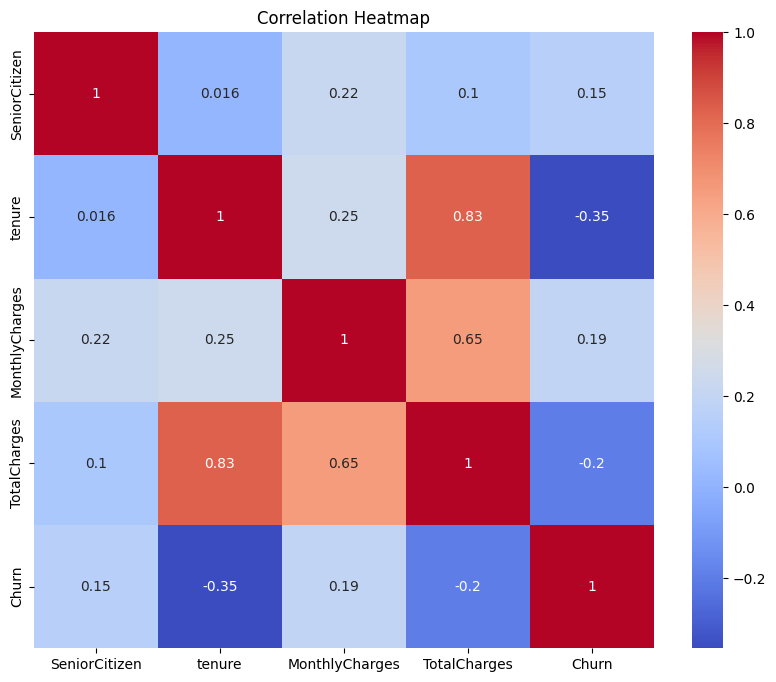

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


In [ ]:
df['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


In [ ]:
df.groupby('Churn') ['MonthlyCharges'].mean()

,MonthlyCharges
Churn,
0,61.307408
1,74.441332


In [ ]:
df.groupby('Churn')['tenure'].mean()

,tenure
Churn,
0,37.650010
1,17.979133


In [ ]:
df.groupby('Churn')['TotalCharges'].mean()

,TotalCharges
Churn,
0,2555.344141
1,1531.796094


In [ ]:
churn_yes=df[df['Churn']== 1]['MonthlyCharges']
churn_no=df[df['Churn']== 0]['MonthlyCharges']
t_statistic,p_value=ttest_ind(churn_yes,churn_no)
print('t-statistic:',t_statistic)
print('p-value:',p_value)

t-statistic: 16.47959313114872
p-value: 6.760843117980302e-60


In [ ]:
if p_value < 0.05:
    print('MonthlyCharges has a statistically significant relatonship with churn ')
else:
    print('MonthlyCharges has no statistically significant relationship with churn')

MonthlyCharges has a statistically significant relatonship with churn 


In [ ]:
churn_yes=df[df['Churn']== 1]['tenure']
churn_no=df[df['Churn']== 0]['tenure']
t_statistic,p_value=ttest_ind(churn_yes,churn_no)
print('t-statistic:',t_statistic)
print('p-value:',p_value)

t-statistic: -31.741289063447653
p-value: 9.437650217574845e-207


In [ ]:
if p_value < 0.05:
    print('tenure has a statistically significant relatonship with churn ')
else:
    print('tenure has no statistically significant relationship with churn')

tenure has a statistically significant relatonship with churn 


In [ ]:
churn_yes=df[df['Churn']== 1]['TotalCharges']
churn_no=df[df['Churn']== 0]['TotalCharges']
t_statistic,p_value=ttest_ind(churn_yes,churn_no)
print('t-statistic:',t_statistic)
print('p-value:',p_value)

t-statistic: -17.068827211220274
p-value: 4.876865689694505e-64


In [ ]:
if p_value < 0.05:
    print('TotalCharges has a statistically significant relatonship with churn ')
else:
    print('TotalCharges has no statistically significant relationship with churn')

TotalCharges has a statistically significant relatonship with churn 


In [ ]:
contingency_table=pd.crosstab(df['gender'],df['Churn'])
chi2,p,dof,expected=chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print('p-value:', p)

Chi-Square Statistic: 0.47545453727386294
p-value: 0.4904884707065509


In [ ]:
if p_value < 0.05:
    print('Gender has a statistically significant relatonship with churn ')
else:
    print('Gender has no statistically significant relationship with churn')

Gender has a statistically significant relatonship with churn 


In [ ]:
contingency_table=pd.crosstab(df['InternetService'],df['Churn'])
chi2,p,dof,expected=chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print('p-value:', p)

Chi-Square Statistic: 728.6956143058694
p-value: 5.831198962237274e-159


In [ ]:
if p < 0.05:
    print('InternetService has a statistically significant relationship with churn')
else:
    print('InternetService has no statistically significant relationship with churn')

InternetService has a statistically significant relationship with churn


In [44]:
#Chi-square test for payment Method vs Churn
contingency_table=pd.crosstab(df['PaymentMethod'],df['Churn'])
chi2,p,dof,expected=chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print('p-value:', p)

Chi-Square Statistic: 645.4299001234638
p-value: 1.4263098511063342e-139


In [45]:
if p < 0.05:
    print('PaymentMethod has a statistically significant relationship with churn')
else:
    print('PaymentMethod has no statistically significant relationship with churn')

PaymentMethod has a statistically significant relationship with churn


In [46]:
#One way ANOVA to contract type and Monthly Charges
month_to_month=df[df['Contract']=='Month-to-month']['MonthlyCharges']
one_year=df[df['Contract']=='One year']['MonthlyCharges']
two_year=df[df['Contract']=='Two year']['MonthlyCharges']
f_state,p_value=f_oneway(month_to_month,one_year,two_year)
print('F-statistic:',f_state)
print('p-value:',p_value)

F-statistic: 19.99855605912631
p-value: 2.1845147673871253e-09


In [47]:
if p < 0.05:
    print('Contract has a statistically significant relationship with MonthyCharges')
else:
    print('Contract has no statistically significant relationship with MonthlyCharges')

Contract has a statistically significant relationship with MonthyCharges


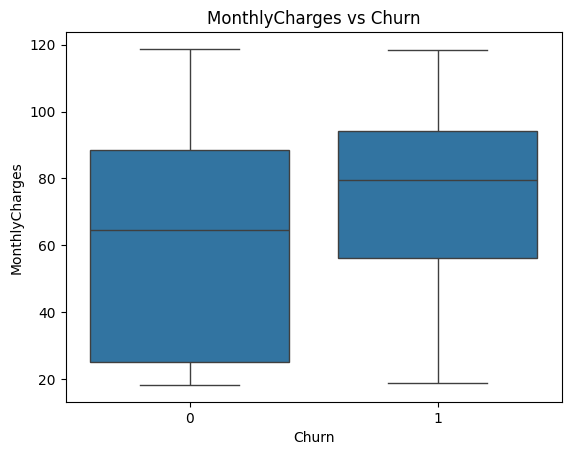

In [48]:
sns.boxplot(x='Churn',y='MonthlyCharges',data=df)
plt.title('MonthlyCharges vs Churn')
plt.show()


In [49]:
print('Statistical Analysis Completed Successfully')

Statistical Analysis Completed Successfully
